Enter the k value:5

Fold 1
Slope M: 4.4404761904761925
Intercept C: 25.571428571428555
Training MSE: 0.09077380952381109
Testing MSE: 0.762825963718839


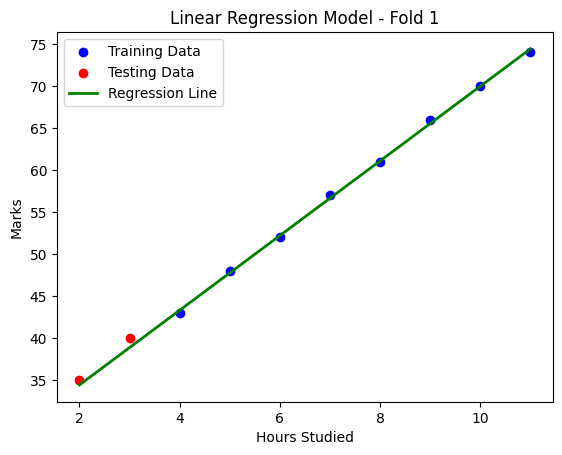


Fold 2
Slope M: 4.333333333333334
Intercept C: 26.541666666666664
Training MSE: 0.10937500000000075
Testing MSE: 0.4045138888888894


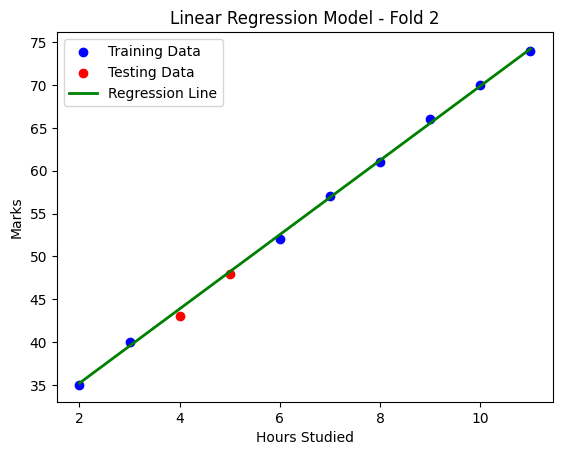


Fold 3
Slope M: 4.359756097560974
Intercept C: 26.286585365853668
Training MSE: 0.15777439024390255
Testing MSE: 0.11810306365258785


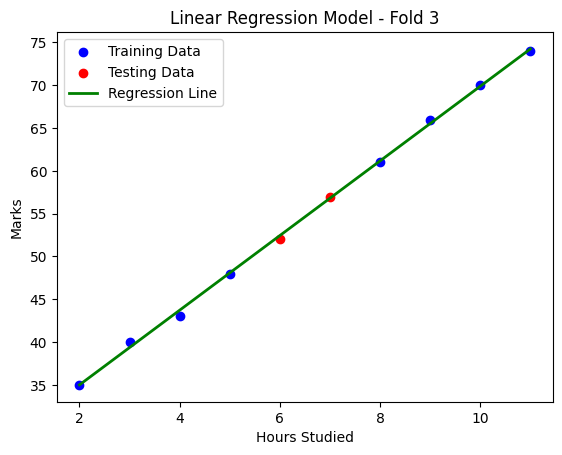


Fold 4
Slope M: 4.347222222222222
Intercept C: 26.291666666666664
Training MSE: 0.1493055555555569
Testing MSE: 0.17255015432099308


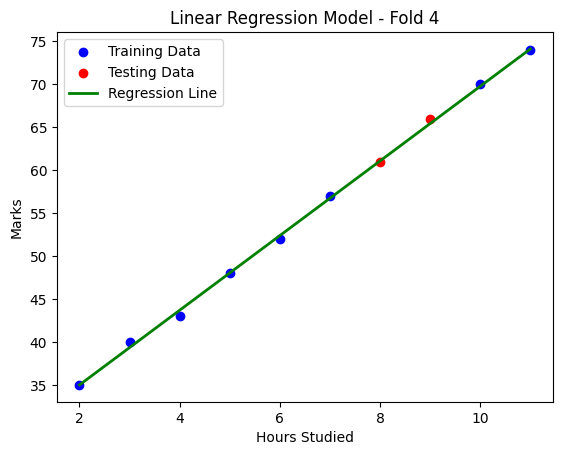


Fold 5
Slope M: 4.380952380952383
Intercept C: 26.15476190476189
Training MSE: 0.17559523809523858
Testing MSE: 0.06023242630385692


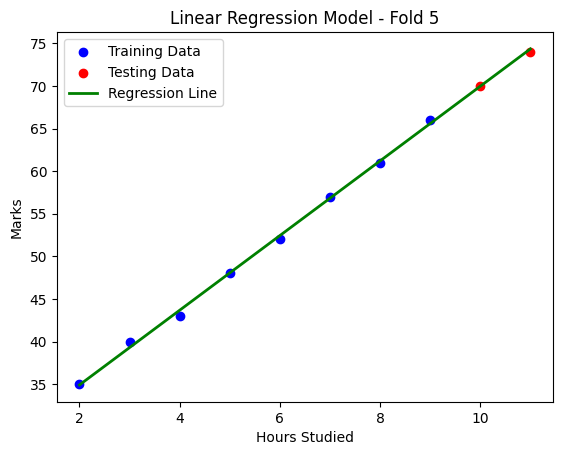


Average Testing MSE: 0.30364509937703327


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

df=pd.read_csv('dataset.csv')

x=df[['Hours_Studied']]
y=df['Marks']
avg=[]
while True:
  k=int(input("Enter the k value:"))
  if k>0 and k<=len(x):
    break
  print("Try Again")

for i in range(k):
 test_low=int((1/k)*len(x)*i)
 test_high=int(test_low+((1/k)*len(x)))

 x_train=pd.concat([x.iloc[:test_low],x.iloc[test_high:]])
 x_test=x.iloc[test_low:test_high]

 y_train=pd.concat([y.iloc[:test_low],y.iloc[test_high:]])
 y_test=y.iloc[test_low:test_high]

 model=LinearRegression()
 model.fit(x_train,y_train)

 print("\nFold",i+1)
 print("Slope M:",model.coef_[0])
 print("Intercept C:",model.intercept_)

 y_train_pred=model.predict(x_train)
 train_mse=mean_squared_error(y_train,y_train_pred)
 print("Training MSE:",train_mse)

 y_test_pred=model.predict(x_test)
 test_mse=mean_squared_error(y_test,y_test_pred)
 print("Testing MSE:",test_mse)

 plt.scatter(x_train,y_train,color='blue',label='Training Data')
 plt.scatter(x_test,y_test,color='red',label='Testing Data')


 x_sorted = x.sort_values(by='Hours_Studied')
 plt.plot(x_sorted,model.predict(x_sorted),color='green',linewidth=2,label='Regression Line')

 plt.xlabel('Hours Studied')
 plt.ylabel('Marks')
 plt.title(f'Linear Regression Model - Fold {i+1}')
 plt.legend()
 plt.show()


 avg.append(test_mse)

print("\nAverage Testing MSE:",sum(avg)/len(avg))